# 02 — Classification : prédire si un événement sera populaire

**Question :** un événement atteindra-t-il au moins 10 RSVP ? (environ 12 % des événements)

Ce notebook **présente et analyse** le modèle de `bandsintown_scraper/model.py`. Il n'en recopie pas le code : il appelle les mêmes fonctions que `python main.py --skip-scraping --train` :

1. comparaison des 3 modèles, chacun avec ses hyperparamètres optimisés ;
2. évaluation du meilleur sur le jeu de test, face à une référence naïve ;
3. analyse des erreurs : matrice de confusion, choix du seuil de décision, courbe ROC ;
4. variables les plus utiles.

Aucune requête n'est envoyée : les données viennent de `data/raw/`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est dans notebooks/ : on se place à la racine du projet
# pour importer le module bandsintown_scraper et lire data/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, precision_score, recall_score
from sklearn.model_selection import train_test_split

from bandsintown_scraper.config import POPULARITY_THRESHOLD, RANDOM_STATE, TEST_SIZE
from bandsintown_scraper.model import build_features, print_report, train_model
from bandsintown_scraper.transform import load_events_dataframe

In [2]:
from matplotlib.ticker import PercentFormatter

# Style des graphiques : une couleur principale, textes en gris foncé, grille discrète
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e1",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})


def plot_rate(labels, rates, counts, title, xlabel, reference=None):
    """Barres de la part d'événements populaires par catégorie, avec l'effectif sous chaque barre."""
    fig, ax = plt.subplots()
    positions = range(len(labels))
    ax.bar(positions, rates, color=BLUE, width=0.6)
    if reference is not None:
        ax.axhline(reference, color=GRAY, linestyle="--", linewidth=1.5)
        ax.text(len(labels) - 0.5, reference, f"moyenne {reference:.0%}", color="#52514e",
                ha="right", va="bottom", fontsize=9)
    ax.set_xticks(list(positions), [f"{label}\n(n={count})" for label, count in zip(labels, counts)])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("part d'événements populaires")
    plt.tight_layout()
    plt.show()

## 1. Entraînement

`train_model` optimise les hyperparamètres des 3 modèles par validation croisée, garde le meilleur et l'évalue sur le jeu de test (environ 1 minute).

In [3]:
events = load_events_dataframe()
model, report = train_model(events)
print_report(report)

  regression_logistique  meilleur ROC-AUC validation croisée : 0.710 (± 0.040)


  random_forest          meilleur ROC-AUC validation croisée : 0.848 (± 0.014)


  gradient_boosting      meilleur ROC-AUC validation croisée : 0.849 (± 0.017)



Meilleur modèle : gradient_boosting
Hyperparamètres choisis : {'l2_regularization': 0.21517, 'learning_rate': 0.01803, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Cible : est_populaire (nb_rsvp >= 10) (12% des 3892 événements)
Jeu de test              modèle  référence
  roc_auc                 0.861      0.525
  f1                      0.468      0.166
  precision               0.343      0.162
  rappel                  0.734      0.170
Variables les plus utiles (perte de ROC-AUC si on les mélange) :
  heure                  0.1258
  nb_evenements_artiste  0.1117
  distance_centre_km     0.1084
  nb_evenements_salle    0.1020
  jour_semaine           0.0087


## 2. Comparaison des modèles (validation croisée)

In [4]:
comparison = pd.DataFrame(report["validation_croisee"]).T
comparison[["roc_auc_moyen", "ecart_type", "hyperparametres"]].sort_values("roc_auc_moyen", ascending=False)

,roc_auc_moyen,ecart_type,hyperparametres
gradient_boosting,0.849,0.017,"{'l2_regularization': 0.21517, 'learning_rate'..."
random_forest,0.848,0.014,"{'n_estimators': 400, 'min_samples_leaf': 10, ..."
regression_logistique,0.71,0.04,{'C': 0.07459}


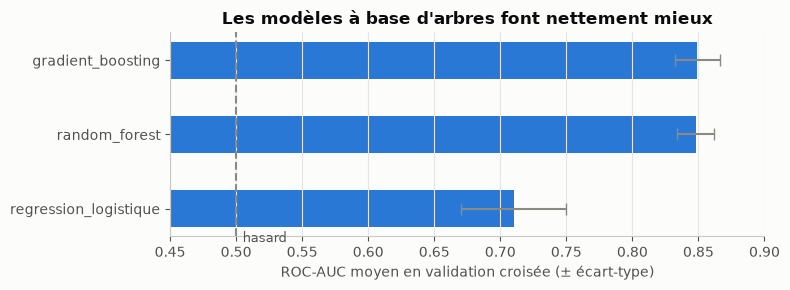

In [5]:
names = comparison.sort_values("roc_auc_moyen").index
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(names, comparison.loc[names, "roc_auc_moyen"], xerr=comparison.loc[names, "ecart_type"],
        color=BLUE, height=0.5, error_kw={"ecolor": GRAY, "capsize": 4})
ax.axvline(0.5, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(0.505, -0.45, "hasard", color="#52514e", fontsize=9)
ax.set_xlim(0.45, 0.9)
ax.set_xlabel("ROC-AUC moyen en validation croisée (± écart-type)")
ax.set_title("Les modèles à base d'arbres font nettement mieux")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
plt.tight_layout()
plt.show()

## 3. Le jeu de test

On reconstruit le même découpage que `train_model` (même graine `RANDOM_STATE`, découpage stratifié) pour analyser les prédictions du modèle sur les événements qu'il n'a jamais vus.

In [6]:
X, y = build_features(events)
_, X_test, _, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
probabilities = model.predict_proba(X_test)[:, 1]
print(f"{len(y_test)} événements de test, dont {y_test.sum()} populaires ({y_test.mean():.0%})")
pd.DataFrame({"modèle": report["test"], "référence naïve": report["test_reference_naive"]})

779 événements de test, dont 94 populaires (12%)


,modèle,référence naïve
roc_auc,0.861,0.525
f1,0.468,0.166
precision,0.343,0.162
rappel,0.734,0.170


## 4. Matrice de confusion (seuil 0,5)

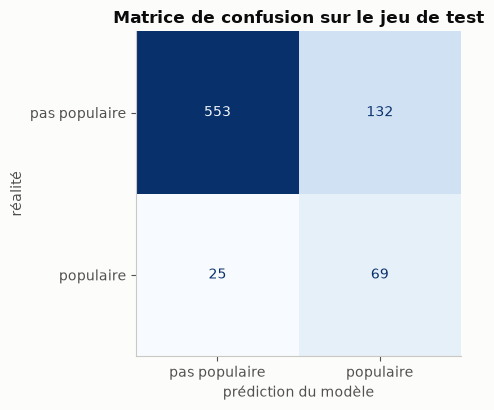

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, (probabilities >= 0.5).astype(int), display_labels=["pas populaire", "populaire"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_xlabel("prédiction du modèle")
ax.set_ylabel("réalité")
ax.set_title("Matrice de confusion sur le jeu de test")
ax.grid(False)
plt.tight_layout()
plt.show()

## 5. Choisir le seuil de décision

Le modèle donne une **probabilité** d'être populaire. Le **seuil** la transforme en décision : au-dessus, on annonce « populaire ».

- Monter le seuil donne moins de fausses alertes (**précision** en hausse), mais fait rater des événements populaires (**rappel** en baisse).
- Le baisser donne l'inverse.

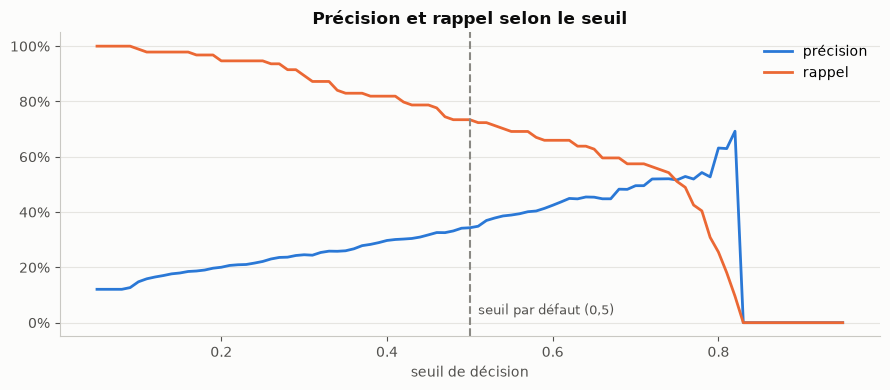

In [8]:
thresholds = np.arange(0.05, 0.96, 0.01)
precisions = [precision_score(y_test, probabilities >= t, zero_division=0) for t in thresholds]
recalls = [recall_score(y_test, probabilities >= t) for t in thresholds]

fig, ax = plt.subplots()
ax.plot(thresholds, precisions, color=BLUE, linewidth=2, label="précision")
ax.plot(thresholds, recalls, color=ORANGE, linewidth=2, label="rappel")
ax.axvline(0.5, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(0.51, 0.03, "seuil par défaut (0,5)", color="#52514e", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlabel("seuil de décision")
ax.set_title("Précision et rappel selon le seuil")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [9]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    predicted = probabilities >= threshold
    rows.append({
        "seuil": threshold,
        "annoncés populaires": int(predicted.sum()),
        "précision": round(precision_score(y_test, predicted, zero_division=0), 2),
        "rappel": round(recall_score(y_test, predicted), 2),
    })
pd.DataFrame(rows)

,seuil,annoncés populaires,précision,rappel
0,0.3,342,0.25,0.89
1,0.4,259,0.30,0.82
2,0.5,201,0.34,0.73
3,0.6,146,0.42,0.66
4,0.7,109,0.50,0.57
5,0.8,38,0.63,0.26


**Les événements que le modèle juge les plus probablement populaires :**

In [10]:
ranking = np.argsort(probabilities)[::-1]
pd.DataFrame([
    {"top": k, "vraiment populaires": int(y_test.values[ranking[:k]].sum()),
     "part": f"{y_test.values[ranking[:k]].mean():.0%}"}
    for k in (10, 20, 50, 100)
])

,top,vraiment populaires,part
0,10,7,70%
1,20,14,70%
2,50,26,52%
3,100,52,52%


## 6. Courbe ROC

Elle résume la qualité du classement pour **tous** les seuils à la fois. L'aire sous la courbe (ROC-AUC) vaut 0,5 pour le hasard (la diagonale) et 1 pour un modèle parfait.

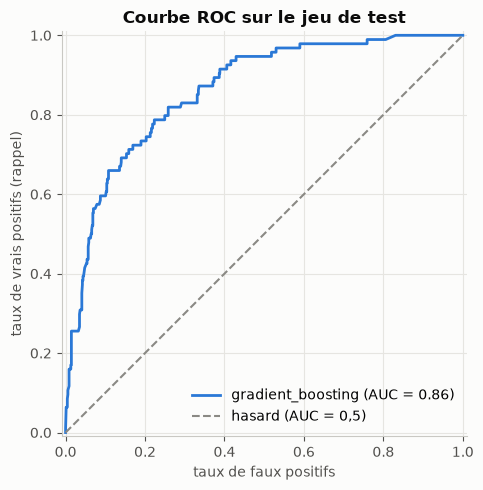

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_test, probabilities, ax=ax, name=report["meilleur_modele"],
                                 curve_kwargs={"color": BLUE, "linewidth": 2})
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1.5, label="hasard (AUC = 0,5)")
ax.set_xlabel("taux de faux positifs")
ax.set_ylabel("taux de vrais positifs (rappel)")
ax.set_title("Courbe ROC sur le jeu de test")
ax.grid(True, axis="both")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 7. Variables les plus utiles

Importance par permutation : de combien le ROC-AUC baisse quand on mélange les valeurs d'une variable.

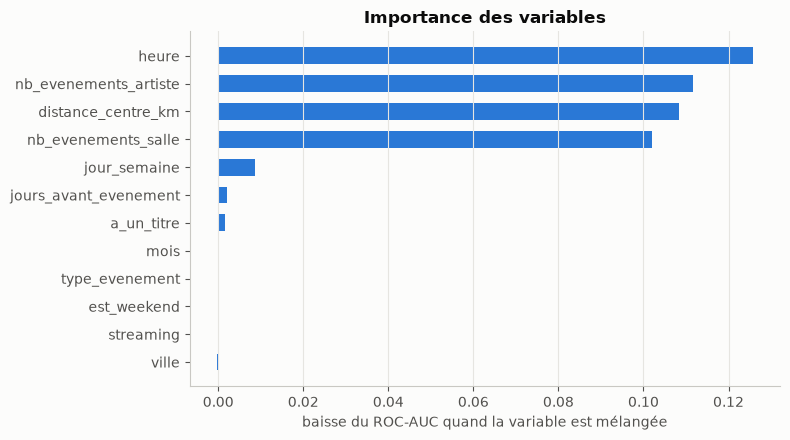

In [12]:
importances = pd.Series(report["importance_variables"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importances.index, importances.values, color=BLUE, height=0.6)
ax.set_xlabel("baisse du ROC-AUC quand la variable est mélangée")
ax.set_title("Importance des variables")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
plt.tight_layout()
plt.show()

## 8. Conclusions

Chiffres de la collecte du 23/10/2026 (3892 événements, dont 779 en test).

**Choix du modèle**
- Les deux modèles à base d'arbres, **gradient boosting (ROC-AUC 0,849)** et random forest (0,848), font nettement mieux que la régression logistique (0,710). Ils captent les effets non réguliers vus dans l'exploration : l'heure, et la distance au centre.
- Gradient boosting et random forest sont **à égalité de fait** : l'écart (0,001) est bien plus petit que la variation d'un pli à l'autre (± 0,015).

**Sur le jeu de test**
- **ROC-AUC de 0,861**, contre 0,525 pour la référence naïve : le modèle classe bien les événements, du moins au plus probablement populaire.
- **Au seuil de 0,5** (matrice de confusion), il retrouve 69 des 94 événements populaires (rappel 0,73), au prix de 132 fausses alertes (précision 0,34).
- **Les événements les mieux classés sont fiables** : 7 des 10 premiers, et 14 des 20 premiers, sont vraiment populaires.

**Choix du seuil**
- **Seuil 0,5** (par défaut) : bon rappel, précision modeste. Adapté pour ne pas rater les événements populaires.
- **Seuil 0,7** : précision 0,50, rappel 0,57, le meilleur compromis (F1).
- **Seuil 0,8** : précision 0,63, mais seulement 26 % des événements populaires sont retrouvés.
- Le seuil se choisit selon l'usage. Pour un choix rigoureux, il faudrait le fixer par validation croisée sur l'entraînement (`TunedThresholdClassifierCV`), et non sur le jeu de test comme ici.

**Variables**
- **Quatre variables portent presque tout le modèle** : l'heure, le nombre de dates de l'artiste, la distance au centre et l'activité de la salle.
- `mois`, `type_evenement`, `est_weekend`, `streaming` et `ville` n'apportent rien de mesurable. On pourrait les retirer pour simplifier le modèle.
- **La piste d'amélioration principale** : une vraie mesure de la notoriété de l'artiste (par exemple son nombre de fans sur Bandsintown), qui manque aujourd'hui.